# Project: Variable renewable energy

[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/mec557/ml4climate/master?urlpath=%2Fdoc%2Ftree%2Fml4climate%2Fnotebooks%2Fproject_vre.ipynb)

***Projet réalisé par: Alexis Capenter, Christian Fahe***

<div class="alert alert-block alert-warning">
    <b>Schedule</b>
    
- Ask your supervisors for the data if not already provided (it is not included in this repository).
- Quick presentation.
- Final project presentation.
    
</div>

<div class="alert alert-block alert-info">
    <b>One problematic, One dataset, One (or more) method(s)</b>
    
- Quality of the dataset is key.
- Results on a clean notebook.
- Explain which method(s) you used and why.
- If a method fails, explain why.

</div>

## Variable Renewable Energy (VRE) assessment and forecast

### Project objectives
<div class="alert alert-block alert-info">

- Assess the solar photovoltaic hourly production over in metropolitan France regions using climate data and capacity factor observations.
- Predict the VRE power ahead of time.
</div>

 1. We will use solar power
 2. Read solar productin=on assesment and forecast
 3. Estimate the hourly solar production

# I- Visualisation des données

## Reading the data

In [28]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import numpy as np
# Directories where you saved the data
data_dir_energy = Path('C:/Projet-VRE/data')
data_dir_climate = Path('C:/Projet-VRE/data/climate_france')

# Template filenames
filename_mask = 'mask_datagouv_french_regions_merra2_Nx_France.nc'
filename_climate = 'merra2_area_selection_output_{}_merra2_2010-2019.nc'
filename_energy = 'reseaux_energies_{}.csv'


Text(0, 0.5, 'Facteur de charge (-)')

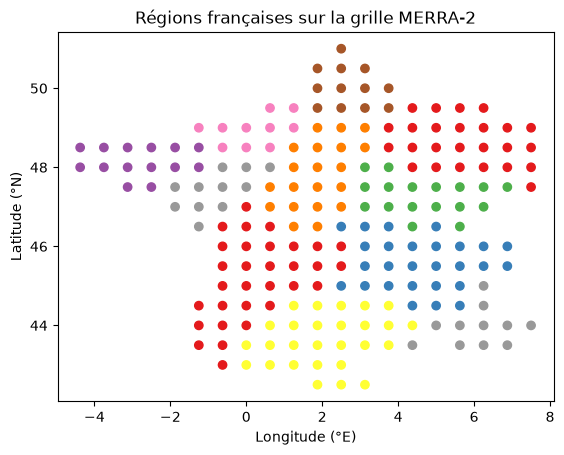

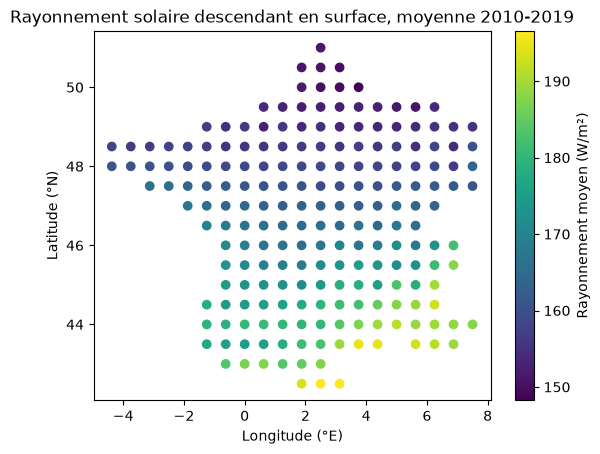

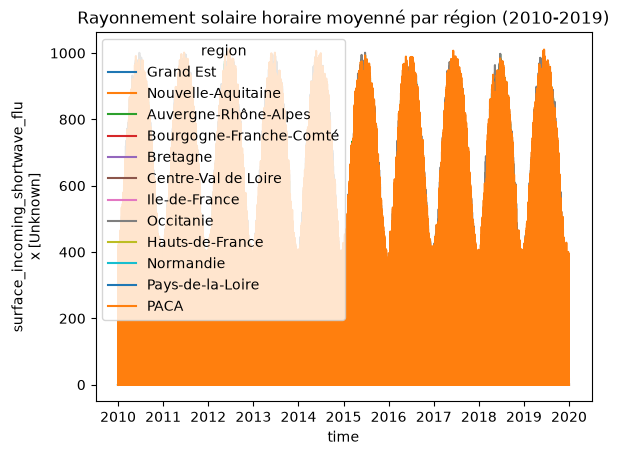

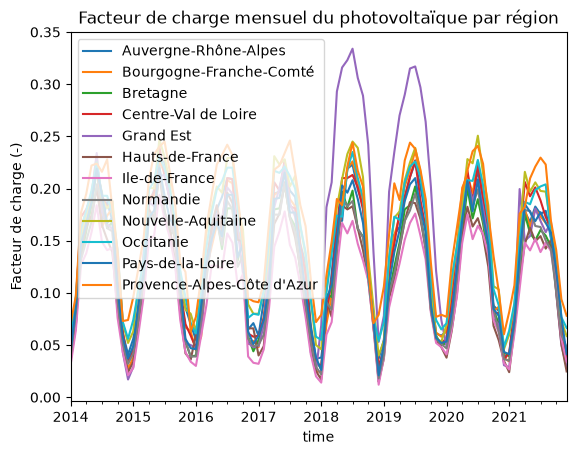

In [ ]:
# Read and plot grid point-region mask
filepath_mask = Path(data_dir_climate, filename_mask)
ds_mask = xr.load_dataset(filepath_mask)
da_mask = ds_mask['mask']
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_mask, cmap='Set1')
plt.title('Régions françaises sur la grille MERRA-2')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Read a climate variable and plot its mean over time
variable_name = 'surface_downward_radiation'
filename = filename_climate.format(variable_name)
filepath = Path(data_dir_climate, filename)
da_climate = xr.load_dataset(filepath)[variable_name]
plt.figure()
plt.scatter(da_mask['lon'], da_mask['lat'], c=da_climate.mean('time'))
plt.colorbar(label='Rayonnement moyen (W/m²)')
plt.title('Rayonnement solaire descendant en surface, moyenne 2010-2019')
plt.xlabel('Longitude (°E)')
plt.ylabel('Latitude (°N)')

# Compute regional mean of climate variable and plot time series
da_climate_reg = da_climate.groupby(da_mask).mean().rename(mask='region')
da_climate_reg['region'] = ds_mask['region'].values
plt.figure()
da_climate_reg.plot.line(x='time')
plt.title('Rayonnement solaire horaire moyenné par région (2010-2019)')

# Read energy variable and plot time series
variable_name = 'capacityfactor_pv'
filename = filename_energy.format(variable_name)
filepath = Path(data_dir_energy, filename)
df_energy = pd.read_csv(filepath, index_col=0, header=0, parse_dates=True)
df_energy = df_energy.rename(columns={'Île-de-France':'Ile-de-France', 'Pays de la Loire':'Pays-de-la-Loire'})
ax = df_energy.plot(title='Facteur de charge mensuel du photovoltaïque par région')
ax.set_ylabel('Facteur de charge (-)')



**Facteur de charge**: Le facteur de charge d'une installation photovoltaïque est le rapport entre l'énergie réellement produite sur une période donnée (par exemple un an) et l'énergie qu'elle aurait produite si elle avait fonctionné en continu à sa puissance nominale (puissance crête)

$\text{Facteur de charge(\%)} = \frac{\text{Energie produite sur la période(kWh)}}{\text{Puissance nominale(kW)} \times \text{nombres d'heures de la période}} \times 100$



Nous devons dans un premier temps moyenner les données par regions avant de faire la prédiction.

On fera la prédiction avec les valeurs mensuelles de **rayonnement solaire** et le **facteur de charge**.

X = **Rayonnement solaire**
 
y = **facteur de charge**

## Transformation des données

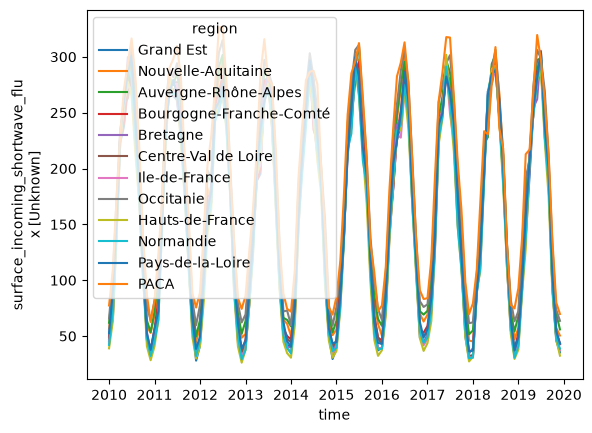

In [77]:
# rayonnement solaire moyen par mois par région
da_monthly_reg = da_climate_reg.resample(time="MS").mean() # valeurs 
da_monthly_reg.plot.line(x='time')
plt.show()

In [78]:
df_monthly_reg = da_monthly_reg.to_pandas()
df_monthly_reg = df_monthly_reg.rename(columns={'PACA':"Provence-Alpes-Côte d'Azur"})
df_monthly_reg

region,Grand Est,Nouvelle-Aquitaine,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Ile-de-France,Occitanie,Hauts-de-France,Normandie,Pays-de-la-Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2010-01-01,45.450001,56.676620,61.891178,49.477009,49.993095,47.721348,43.559608,65.690071,39.006538,42.091908,52.568775,77.393494
2010-02-01,66.637657,93.542099,96.567177,78.436684,82.344009,81.132645,71.057167,106.283760,63.949310,73.317558,90.696899,109.889809
2010-03-01,139.414459,161.307190,159.204163,141.713379,141.412781,145.349854,141.006073,169.882980,134.733276,141.040253,149.670944,170.826630
2010-04-01,223.208099,232.158630,227.278168,229.187103,233.302261,230.400177,226.640015,235.345535,223.779205,228.440170,231.981140,230.358200
2010-05-01,237.565063,251.229370,241.437653,240.941452,252.884750,258.408844,260.374359,255.147659,257.621429,264.853119,260.300690,271.362640
...,...,...,...,...,...,...,...,...,...,...,...,...
2019-08-01,236.886841,261.075470,254.129913,245.967255,232.624069,242.315811,228.612228,269.474976,224.611313,227.697037,237.988159,260.528564
2019-09-01,185.411636,205.671326,203.320786,194.291122,189.449432,198.447159,190.179108,210.394104,174.672607,186.869034,200.403687,212.587753
2019-10-01,94.647316,117.320702,114.376587,97.457878,102.922546,100.030853,93.818886,132.098038,89.426201,94.100342,105.592949,135.715454


In [79]:
df_energy_join, df_monthly_reg_join = df_energy.align(df_monthly_reg, join='inner', axis=0) # avoir les mêmes indexes


In [80]:
df_energy_join

,Auvergne-Rhône-Alpes,Bourgogne-Franche-Comté,Bretagne,Centre-Val de Loire,Grand Est,Hauts-de-France,Ile-de-France,Normandie,Nouvelle-Aquitaine,Occitanie,Pays-de-la-Loire,Provence-Alpes-Côte d'Azur
time,,,,,,,,,,,,
2014-01-01,0.051,0.048,0.045,0.048,0.044,0.035,0.031,0.038,0.053,0.057,0.044,0.070
2014-02-01,0.079,0.078,0.081,0.092,0.068,0.068,0.064,0.081,0.088,0.096,0.086,0.097
2014-03-01,0.156,0.161,0.134,0.173,0.156,0.141,0.127,0.132,0.154,0.162,0.147,0.177
2014-04-01,0.174,0.179,0.159,0.180,0.169,0.163,0.138,0.150,0.174,0.179,0.167,0.195
2014-05-01,0.187,0.195,0.184,0.194,0.193,0.174,0.158,0.168,0.189,0.198,0.187,0.222
...,...,...,...,...,...,...,...,...,...,...,...,...
2019-08-01,0.202,0.213,0.173,0.189,0.297,0.171,0.155,0.174,0.216,0.211,0.182,0.218
2019-09-01,0.174,0.187,0.146,0.162,0.264,0.142,0.132,0.142,0.182,0.177,0.158,0.190
2019-10-01,0.104,0.098,0.085,0.084,0.202,0.087,0.081,0.083,0.108,0.113,0.089,0.129


## Corrélation entre les données

In [88]:
regions = ['Grand Est', 'Nouvelle-Aquitaine', 'Auvergne-Rhône-Alpes',
       'Bourgogne-Franche-Comté', 'Bretagne', 'Centre-Val de Loire',
       'Ile-de-France', 'Occitanie', 'Hauts-de-France', 'Normandie',
       'Pays-de-la-Loire', "Provence-Alpes-Côte d'Azur"]

list_corr = {}
for region in regions:
    list_corr[region] = np.corrcoef(df_energy_join[region], df_monthly_reg_join[region])[0, 1]

list_corr


{'Grand Est': np.float64(0.8243425422615527),
 'Nouvelle-Aquitaine': np.float64(0.9758379430021866),
 'Auvergne-Rhône-Alpes': np.float64(0.9853456758190685),
 'Bourgogne-Franche-Comté': np.float64(0.9756175305041743),
 'Bretagne': np.float64(0.9740209413307362),
 'Centre-Val de Loire': np.float64(0.9816103862291615),
 'Ile-de-France': np.float64(0.9734477131751111),
 'Occitanie': np.float64(0.9873309408953251),
 'Hauts-de-France': np.float64(0.9673577096778141),
 'Normandie': np.float64(0.9778535058123516),
 'Pays-de-la-Loire': np.float64(0.9804355878657938),
 "Provence-Alpes-Côte d'Azur": np.float64(0.9856206529199842)}

On remarque un fort coefficient de correlation entre le facteur de charge et le rayonneemnt moyenne par mois par région.

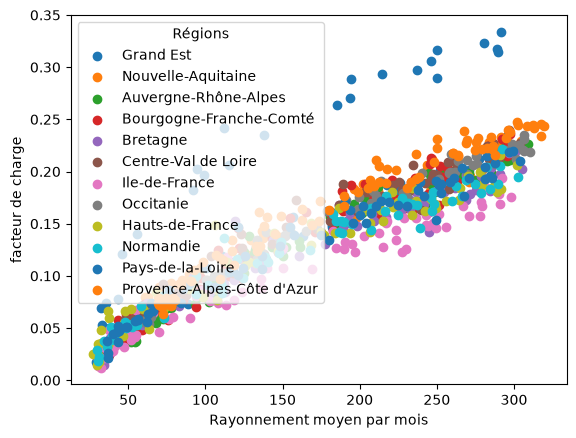

In [96]:
for col in regions:
    plt.scatter(df_monthly_reg_join[col], df_energy_join[col], label=col)

plt.xlabel('Rayonnement moyen par mois')
plt.ylabel('facteur de charge')
plt.legend(title='Régions')
plt.show()

# II- Régression linéaire

In [97]:
X = df_monthly_reg_join['Auvergne-Rhône-Alpes'].to_numpy().reshape((-1,1))
y = df_energy_join['Auvergne-Rhône-Alpes'].to_numpy()


In [ ]:
from sklearn import linear_model
dict_models = {}
for col in regions:
    X = df_monthly_reg_join[col].to_numpy().reshape((-1,1))
    y = df_energy_join[col].to_numpy()
    model = linear_model.LinearRegression()
    model.fit(X, y)
    dict_models[col] = model
dict_models


{'Grand Est': LinearRegression(),
 'Nouvelle-Aquitaine': LinearRegression(),
 'Auvergne-Rhône-Alpes': LinearRegression(),
 'Bourgogne-Franche-Comté': LinearRegression(),
 'Bretagne': LinearRegression(),
 'Centre-Val de Loire': LinearRegression(),
 'Ile-de-France': LinearRegression(),
 'Occitanie': LinearRegression(),
 'Hauts-de-France': LinearRegression(),
 'Normandie': LinearRegression(),
 'Pays-de-la-Loire': LinearRegression(),
 "Provence-Alpes-Côte d'Azur": LinearRegression()}

In [101]:
scores = {}
for col in regions:
    X = df_monthly_reg_join[col].to_numpy().reshape((-1,1))
    y = df_energy_join[col].to_numpy()
    scores[col] = dict_models[col].score(X, y)

scores

{'Grand Est': 0.6795406179727086,
 'Nouvelle-Aquitaine': 0.9522596915765627,
 'Auvergne-Rhône-Alpes': 0.9709061034439989,
 'Bourgogne-Franche-Comté': 0.9518295679605752,
 'Bretagne': 0.9487168050381098,
 'Centre-Val de Loire': 0.9635589503492945,
 'Ile-de-France': 0.9476004525245592,
 'Occitanie': 0.9748223816281459,
 'Hauts-de-France': 0.9357809460346282,
 'Normandie': 0.9561974771499866,
 'Pays-de-la-Loire': 0.9612539349626912,
 "Provence-Alpes-Côte d'Azur": 0.9714480708911627}

On remarque que les scores pour toutes les regions sont au dessus de $0.9$ sauf celui de la région Grand Est. 

Nous allons donc dans la suite, travailler seulement sur cette région afin d'améliorer ce score.

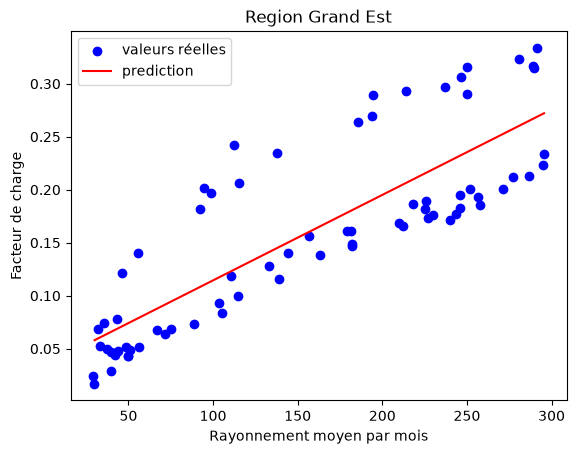

In [ ]:
# Exemple: Grand Est
region = 'Grand Est'
model_GE = dict_models[region]
X_train = df_monthly_reg_join[region].to_numpy()
y_train = df_energy_join[region].to_numpy()
x = np.linspace(X_train.min(), X_train.max(), 30)
X = x.reshape((-1,1))
y_predict = model_GE.predict(X)
plt.scatter(X_train, y_train, color='b', label='valeurs réelles')
plt.plot(x, y_predict, color='r', label='prediction')
plt.xlabel('Rayonnement moyen par mois')
plt.ylabel('Facteur de charge')
plt.title(f'Region {region}')
plt.legend()
plt.show()

***
## Credit

[//]: # "This notebook is part of [E4C Interdisciplinary Center - Education](https://gitlab.in2p3.fr/energy4climate/public/education)."
Contributors include Bruno Deremble and Alexis Tantet.
Several slides and images are taken from the very good [Scikit-learn course](https://inria.github.io/scikit-learn-mooc/).

<br>

<div style="display: flex; height: 70px">
    
<img alt="Logo LMD" src="images/logos/logo_lmd.jpg" style="display: inline-block"/>

<img alt="Logo IPSL" src="images/logos/logo_ipsl.png" style="display: inline-block"/>

<img alt="Logo E4C" src="images/logos/logo_e4c_final.png" style="display: inline-block"/>

<img alt="Logo EP" src="images/logos/logo_ep.png" style="display: inline-block"/>

<img alt="Logo SU" src="images/logos/logo_su.png" style="display: inline-block"/>

<img alt="Logo ENS" src="images/logos/logo_ens.jpg" style="display: inline-block"/>

<img alt="Logo CNRS" src="images/logos/logo_cnrs.png" style="display: inline-block"/>
    
</div>

<hr>

<div style="display: flex">
    <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/"><img alt="Creative Commons License" style="border-width:0; margin-right: 10px" src="https://i.creativecommons.org/l/by-sa/4.0/88x31.png" /></a>
    <br>This work is licensed under a &nbsp; <a rel="license" href="http://creativecommons.org/licenses/by-sa/4.0/">Creative Commons Attribution-ShareAlike 4.0 International License</a>.
</div>